# Análise exploratória · Enchentes em Porto Alegre (INCT SiMAI)

Fase 2 do projeto extensionista. Este notebook explora:

- **Tela 1:** o `data.json` do INCT, antes e depois da limpeza (`scripts/limpeza_inct.py`);
- **Tela 2:** a base externa da UFRGS sobre as cheias de maio de 2024 (`scripts/coleta_zenodo.py` e `scripts/processa_tela2.py`).

Para rodar: execute antes os scripts da pasta `scripts/` (ver README). Os números são **estimativas de uma simulação**, não contagens oficiais.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "scripts"))
from limpeza_inct import carregar_longo

PROC = RAIZ / "dados" / "processados"
AZUL, LARANJA, CINZA = "#2f6ea5", "#b8621b", "#8a8f98"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

bruto = carregar_longo()                         # data.json em formato longo, sem tratamento
limpo = pd.read_csv(PROC / "inct_limpo.csv")     # depois da limpeza
erros = pd.read_csv(PROC / "inct_inconsistencias.csv")
area = pd.read_csv(PROC / "ufrgs_area_bairro.csv")
escolas = pd.read_csv(PROC / "escolas_poa.csv")
print(bruto.shape, limpo.shape, len(erros), "valores corrigidos")
bruto.head()

(6674, 7) (6674, 11) 17 valores corrigidos


,nivel_m,bairro,affected_buildings,total_buildings,percentage,population,affected_population
0,3.0,Aberta dos Morros,0,4696,0,9854,0
1,3.1,Aberta dos Morros,0,4696,0,9854,0
2,3.2,Aberta dos Morros,0,4696,0,9854,0
3,3.3,Aberta dos Morros,0,4696,0,9854,0
4,3.4,Aberta dos Morros,1,4696,1,9854,99


## 1. Estrutura do arquivo do INCT

Antes de qualquer gráfico, conferimos o que o enunciado pede para não assumir: mesmos bairros, mesma ordem e mesma estrutura em todos os níveis.

In [2]:
import json
raw = json.load(open(RAIZ / "dados" / "originais" / "data.json", encoding="utf-8"))
ordem_base = list(raw["3_0m"])
print("níveis:", len(raw), "| bairros por nível:", {len(b) for b in raw.values()})
print("níveis com os bairros em outra ordem:", [n for n, b in raw.items() if list(b) != ordem_base])
print("total_buildings e population constantes por bairro:",
      bool((bruto.groupby("bairro")[["total_buildings", "population"]].nunique() == 1).all().all()))
print("valores negativos:", int((bruto.select_dtypes("number") < 0).sum().sum()),
      "| afetados > total:", int((bruto.affected_buildings > bruto.total_buildings).sum()))

níveis: 71 | bairros por nível: {94}
níveis com os bairros em outra ordem: ['5_3m']
total_buildings e population constantes por bairro: True
valores negativos: 0 | afetados > total: 0


**Leitura:** são 71 níveis com os mesmos 94 bairros e os mesmos 5 campos. O nível **5,3 m vem com os bairros em outra ordem**, então o carregamento usa sempre a chave (nome do bairro), nunca a posição. Não há valores negativos nem impossíveis; os problemas estão na evolução entre níveis e nos campos calculados (seções 2 e 3).

## 2. Inconsistência 1: prédios afetados que diminuem quando o rio sobe

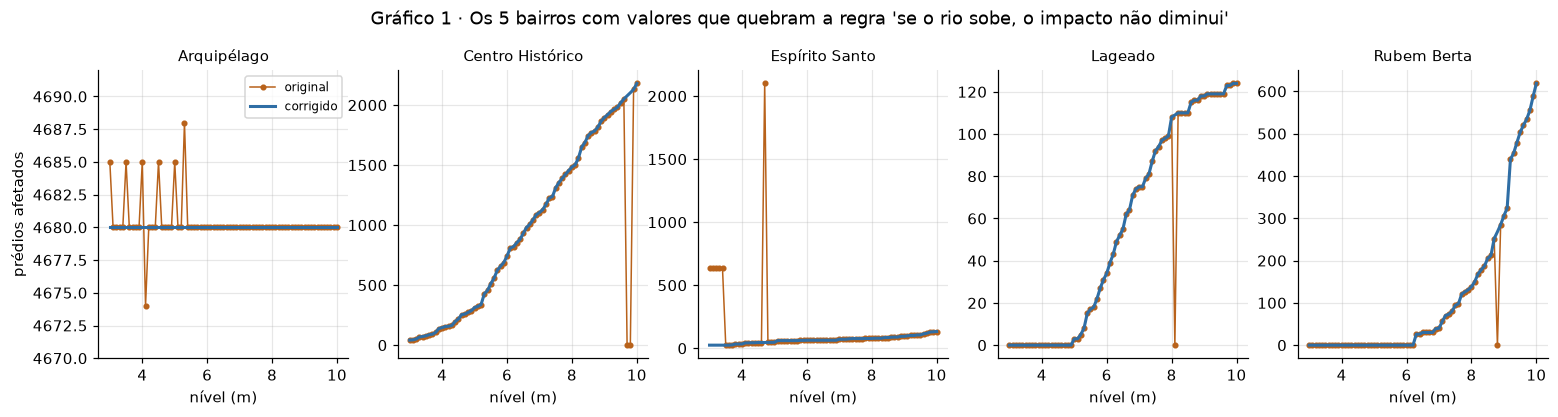

,bairro,problema,valores
0,Arquipélago,valor abaixo da tendência (queda),1
1,Arquipélago,valor acima da tendência (pico),6
2,Centro Histórico,zero isolado (falha de registro),2
3,Espírito Santo,valor acima da tendência (pico),6
4,Lageado,zero isolado (falha de registro),1
5,Rubem Berta,zero isolado (falha de registro),1


In [3]:
bairros_erro = erros["bairro"].unique()
fig, eixos = plt.subplots(1, len(bairros_erro), figsize=(17, 3.4))
for ax, b in zip(eixos, bairros_erro):
    o, l = bruto[bruto.bairro == b], limpo[limpo.bairro == b]
    ax.plot(o.nivel_m, o.affected_buildings, color=LARANJA, lw=1, marker="o", ms=3, label="original")
    ax.plot(l.nivel_m, l.affected_buildings, color=AZUL, lw=2, label="corrigido")
    if b == "Arquipélago":
        ax.set_ylim(4670, 4692)
    ax.set_title(b, fontsize=10); ax.set_xlabel("nível (m)")
eixos[0].set_ylabel("prédios afetados"); eixos[0].legend(fontsize=8)
fig.suptitle("Gráfico 1 · Os 5 bairros com valores que quebram a regra 'se o rio sobe, o impacto não diminui'", y=1.04)
plt.show()
erros.groupby(["bairro", "problema"]).size().rename("valores").reset_index()

**Leitura:** se o rio sobe, um prédio alagado não pode "secar". Em 5 bairros a série original quebra essa regra, com três padrões:

- **Zeros isolados** (Centro Histórico em 9,7 e 9,8 m; Lageado em 8,1 m; Rubem Berta em 8,8 m): o valor cai a zero e volta no nível seguinte. Parece falha de registro.
- **Picos** (Espírito Santo: 637 prédios de 3,0 a 3,4 m e 2.101 em 4,7 m, quando os vizinhos têm entre 25 e 47): o bairro só chega a 133 prédios em 10 m, então esses valores são impossíveis.
- **Ruído pequeno** (Arquipélago oscila entre 4.674 e 4.688 em torno de 4.680).

**Tratamento:** para cada bairro mantemos a maior sequência de pontos que não decresce (ou seja, descartamos o menor número possível de pontos) e interpolamos linearmente os descartados. Foram **17 valores em 5 bairros**. Tudo fica registrado em `inct_inconsistencias.csv` e a coluna `corrigido` marca as linhas alteradas.

## 3. Inconsistência 2: porcentagem arredondada para cima

percentage == teto(exata): 6672 de 6674
percentage == arredondamento normal: 5379
     nivel_m            bairro  affected_buildings  total_buildings  \
752      7.2  Boa Vista do Sul                 686             2450   
753      7.3  Boa Vista do Sul                 686             2450   

     percentage  exata  
752          29   28.0  
753          29   28.0  


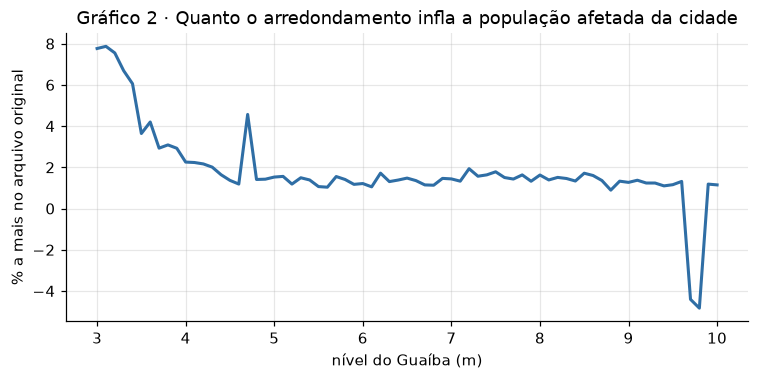

In [4]:
exata = 100 * bruto.affected_buildings / bruto.total_buildings
print("percentage == teto(exata):", int((np.ceil(exata) == bruto.percentage).sum()), "de", len(bruto))
print("percentage == arredondamento normal:", int((exata.round() == bruto.percentage).sum()))
print(bruto[np.ceil(exata) != bruto.percentage].assign(exata=exata)[
    ["nivel_m", "bairro", "affected_buildings", "total_buildings", "percentage", "exata"]])

cidade = limpo.groupby("nivel_m")[["affected_population", "affected_population_orig"]].sum()
excesso = 100 * (cidade.affected_population_orig / cidade.affected_population - 1)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(excesso.index, excesso.values, color=AZUL, lw=2)
ax.set(xlabel="nível do Guaíba (m)", ylabel="% a mais no arquivo original",
       title="Gráfico 2 · Quanto o arredondamento infla a população afetada da cidade")
plt.show()

**Leitura:** o campo `percentage` é sempre um inteiro arredondado **para cima** (6.672 das 6.674 linhas). Como `affected_population = population × percentage / 100`, o erro se propaga: um bairro com 0,1% dos prédios afetados conta 1% da população. No total da cidade, o arquivo original mostra **7,8% mais pessoas a 3,0 m** e cerca de 1,5% a mais perto do nível de 2024.

As 2 linhas que fogem da regra são do bairro Boa Vista do Sul (7,2 e 7,3 m): 686 / 2450 dá exatamente 28%, mas o arquivo traz 29%. É um erro de ponto flutuante (o cálculo dá 28,000000000000004 e o teto vira 29).

**Tratamento:** recalculamos `percentage` (2 casas) e `affected_population` diretamente de `affected_buildings / total_buildings`. Os valores originais ficam nas colunas `*_orig`.

## 4. Tela 1: o que a simulação mostra

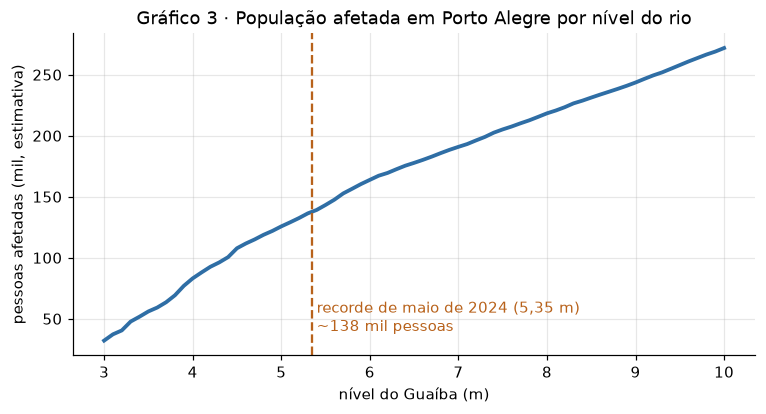

população total: 1,332,845


In [5]:
cidade = limpo.groupby("nivel_m")["affected_population"].sum()
no_recorde = np.interp(5.35, cidade.index, cidade.values)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(cidade.index, cidade.values / 1e3, color=AZUL, lw=2.5)
ax.axvline(5.35, color=LARANJA, ls="--")
ax.annotate(f"recorde de maio de 2024 (5,35 m)\n~{no_recorde / 1e3:.0f} mil pessoas", (5.4, 40), color=LARANJA)
ax.set(xlabel="nível do Guaíba (m)", ylabel="pessoas afetadas (mil, estimativa)",
       title="Gráfico 3 · População afetada em Porto Alegre por nível do rio")
plt.show()
print(f"população total: {limpo[limpo.nivel_m == 3].population.sum():,}")

**Leitura:** a 3,0 m a simulação já estima cerca de 32 mil pessoas afetadas, e no nível recorde de 2024 (5,35 m) cerca de **138 mil, em torno de 10% da população**. A curva é mais inclinada entre 3,5 e 4,5 m (até uns 70 mil pessoas a mais por metro) e fica mais suave depois de 5 m (uns 30 mil por metro): as áreas baixas e populosas enchem primeiro.

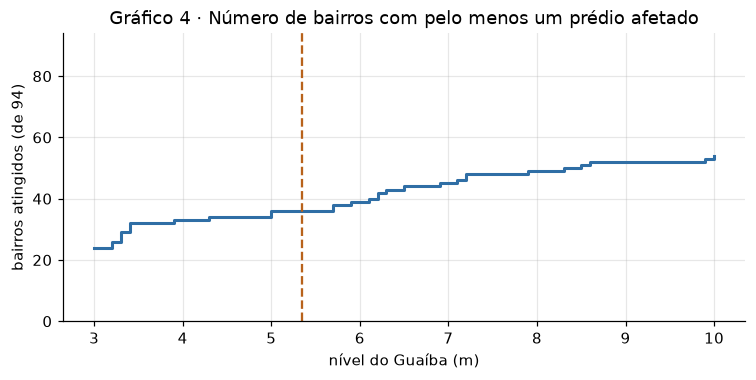

In [6]:
atingidos = limpo[limpo.affected_buildings > 0].groupby("nivel_m")["bairro"].nunique()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.step(atingidos.index, atingidos.values, where="post", color=AZUL, lw=2)
ax.axvline(5.35, color=LARANJA, ls="--")
ax.set(xlabel="nível do Guaíba (m)", ylabel="bairros atingidos (de 94)", ylim=(0, 94),
       title="Gráfico 4 · Número de bairros com pelo menos um prédio afetado")
plt.show()

**Leitura:** 24 bairros já aparecem atingidos a 3,0 m, 36 no nível de 2024 e 54 a 10,0 m. **40 dos 94 bairros nunca são atingidos** na simulação, nem a 10 m. O impacto é concentrado na faixa baixa da cidade, perto do Guaíba, do Gravataí e do arroio Dilúvio.

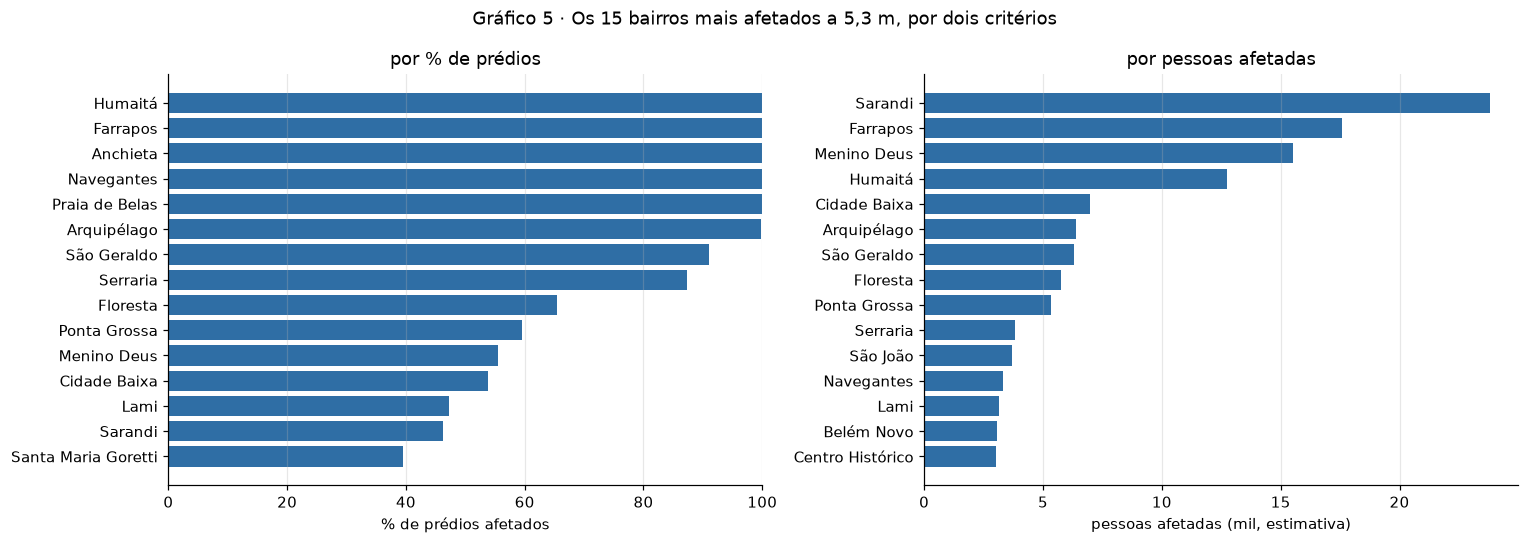

In [7]:
n53 = limpo[np.isclose(limpo.nivel_m, 5.3) & (limpo.affected_buildings > 0)]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
t = n53.nlargest(15, "percentage").sort_values("percentage")
a1.barh(t.bairro, t.percentage, color=AZUL); a1.set(xlabel="% de prédios afetados", xlim=(0, 100))
a1.set_title("por % de prédios")
t = n53.nlargest(15, "affected_population").sort_values("affected_population")
a2.barh(t.bairro, t.affected_population / 1e3, color=AZUL); a2.set(xlabel="pessoas afetadas (mil, estimativa)")
a2.set_title("por pessoas afetadas")
for a in (a1, a2): a.grid(axis="y", visible=False)
fig.suptitle("Gráfico 5 · Os 15 bairros mais afetados a 5,3 m, por dois critérios")
plt.tight_layout(); plt.show()

**Leitura:** os dois rankings contam histórias diferentes. Por porcentagem, lideram bairros totalmente alagados (Farrapos, Humaitá, Navegantes, Anchieta, Praia de Belas e Arquipélago, todos perto de 100%). Por pessoas, o primeiro é **Sarandi** (cerca de 24 mil), com menos da metade dos prédios afetados, porque é muito populoso. Os 5 primeiros bairros somam 56% da população afetada. Por isso o ranking da Tela 1 permite escolher o critério.

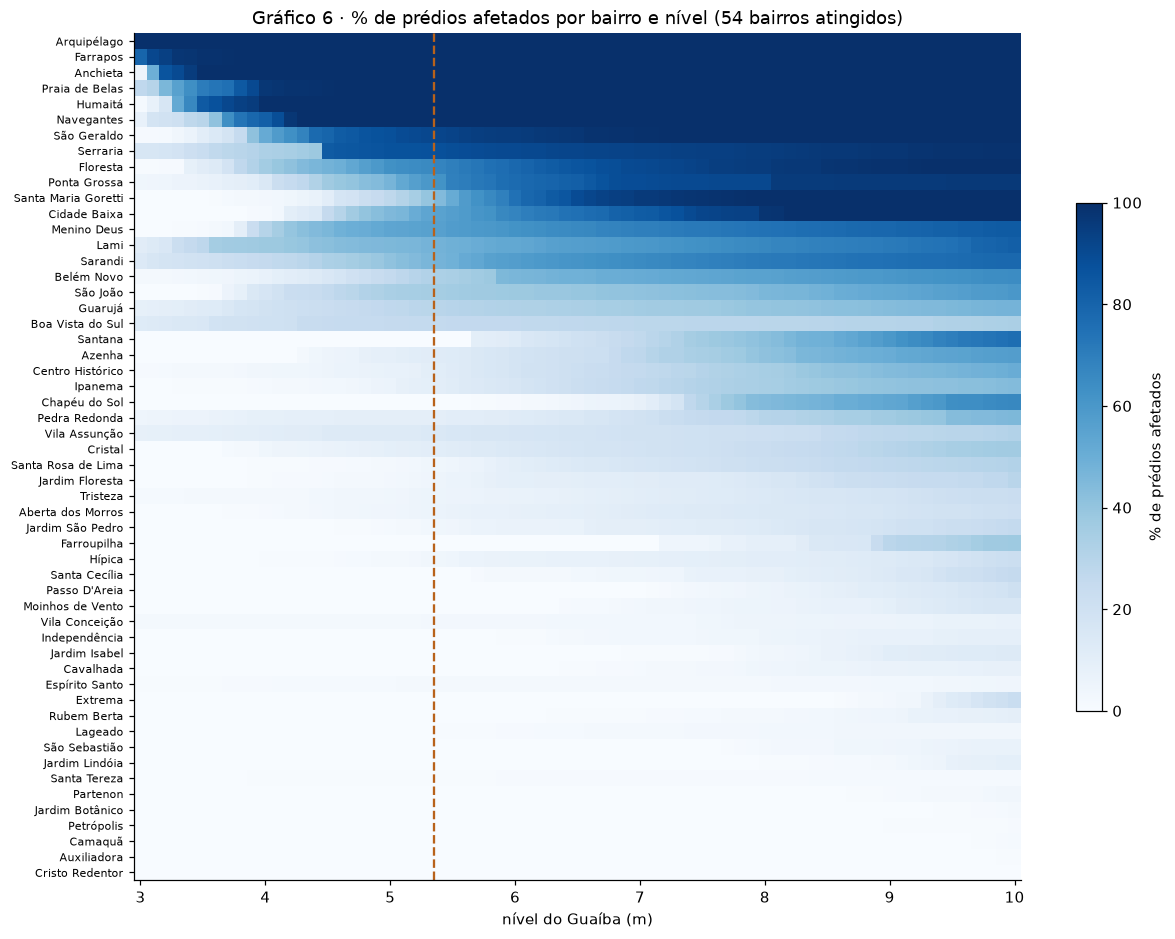

In [8]:
tab = limpo.pivot(index="bairro", columns="nivel_m", values="percentage")
tab = tab[tab.max(axis=1) > 0]
tab = tab.loc[tab.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(13, 10))
im = ax.imshow(tab.values, aspect="auto", cmap="Blues", vmin=0, vmax=100,
               extent=[2.95, 10.05, len(tab), 0])
ax.set_yticks(np.arange(len(tab)) + 0.5, tab.index, fontsize=7)
ax.axvline(5.35, color=LARANJA, ls="--"); ax.grid(False)
ax.set(xlabel="nível do Guaíba (m)", title="Gráfico 6 · % de prédios afetados por bairro e nível (54 bairros atingidos)")
fig.colorbar(im, label="% de prédios afetados", shrink=0.6)
plt.show()

**Leitura:** dá para ver três grupos. (1) Bairros que já começam quase todos alagados e saturam cedo (Arquipélago desde 3,0 m; Anchieta, Farrapos, Humaitá, Navegantes e Praia de Belas chegam a 100% entre 3,5 e 4,6 m). (2) Bairros que crescem aos poucos ao longo de toda a faixa (Sarandi, Floresta, Menino Deus, Cidade Baixa). (3) Bairros que só aparecem em níveis muito acima do recorde (18 bairros só são atingidos acima de 5,35 m). O mapa de calor também confirma que, depois da limpeza, nenhuma linha "volta" para um tom mais claro.

## 5. Tela 2: a base da UFRGS sobre maio de 2024

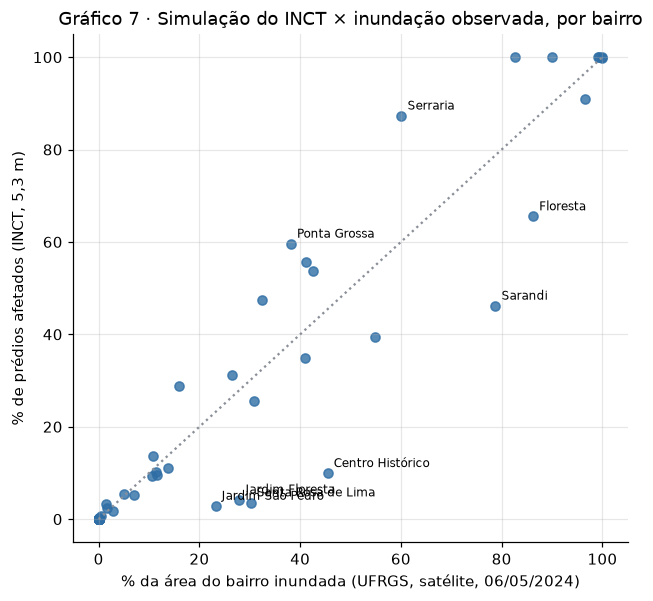

correlação de Pearson: 0.955
bairros com diferença até 10 p.p.: 80 | acima de 20 p.p.: 8


In [9]:
OBS = "rhguaiba_planet-skysat_inundacao_obs_20240506"
comp = n53_todos = limpo[np.isclose(limpo.nivel_m, 5.3)][["bairro", "percentage", "population"]].merge(
    area[area.camada == OBS][["bairro", "pct_area"]], on="bairro")
comp["dif"] = comp.percentage - comp.pct_area
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(comp.pct_area, comp.percentage, color=AZUL, alpha=0.8)
ax.plot([0, 100], [0, 100], color=CINZA, ls=":")
for _, r in comp[comp.dif.abs() > 20].iterrows():
    ax.annotate(r.bairro, (r.pct_area, r.percentage), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set(xlabel="% da área do bairro inundada (UFRGS, satélite, 06/05/2024)",
       ylabel="% de prédios afetados (INCT, 5,3 m)",
       title="Gráfico 7 · Simulação do INCT × inundação observada, por bairro")
plt.show()
print("correlação de Pearson:", round(comp.percentage.corr(comp.pct_area), 3))
print("bairros com diferença até 10 p.p.:", int((comp.dif.abs() <= 10).sum()),
      "| acima de 20 p.p.:", int((comp.dif.abs() > 20).sum()))

**Leitura:** a simulação do INCT a 5,3 m acompanha bem a mancha observada por satélite: **correlação de 0,96** entre os 94 bairros, e 80 deles com diferença de até 10 pontos percentuais (58 porque as duas bases dizem "não atingido"). Em 8 bairros a diferença passa de 20 p.p.

**Cuidado na interpretação:** as medidas são diferentes. O INCT conta *prédios* e a UFRGS mede *área*. No Centro Histórico, por exemplo, a UFRGS indica 45% da área inundada e o INCT 10% dos prédios: a faixa do cais e da orla ocupa muita área e tem poucos prédios. Divergência não significa, sozinha, erro de uma das bases.

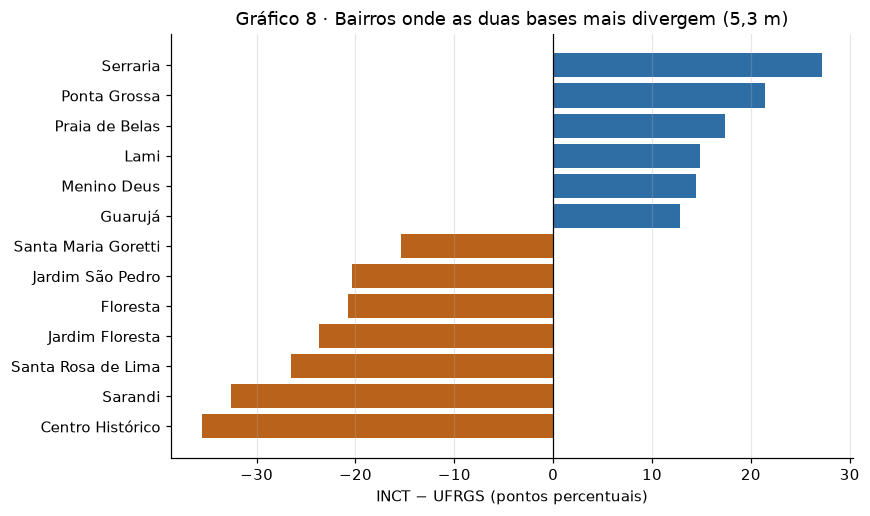

In [10]:
t = comp[comp.dif.abs() > 12].sort_values("dif")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(t.bairro, t.dif, color=np.where(t.dif < 0, LARANJA, AZUL))
ax.axvline(0, color="black", lw=0.8); ax.grid(axis="y", visible=False)
ax.set(xlabel="INCT − UFRGS (pontos percentuais)",
       title="Gráfico 8 · Bairros onde as duas bases mais divergem (5,3 m)")
plt.show()

**Leitura:** em laranja, bairros onde o INCT indica **menos** impacto que a mancha observada (Centro Histórico, Sarandi, Santa Rosa de Lima, Jardim Floresta, Floresta, Jardim São Pedro). Em azul, onde indica **mais** (Serraria, Ponta Grossa, Praia de Belas, Lami, Menino Deus). Uma hipótese para o segundo grupo, a confirmar com o INCT: a simulação não considera o sistema de proteção (diques e casas de bomba), e a imagem de satélite é de um dia depois do pico. Esses bairros são bons candidatos para a devolutiva ao INCT.

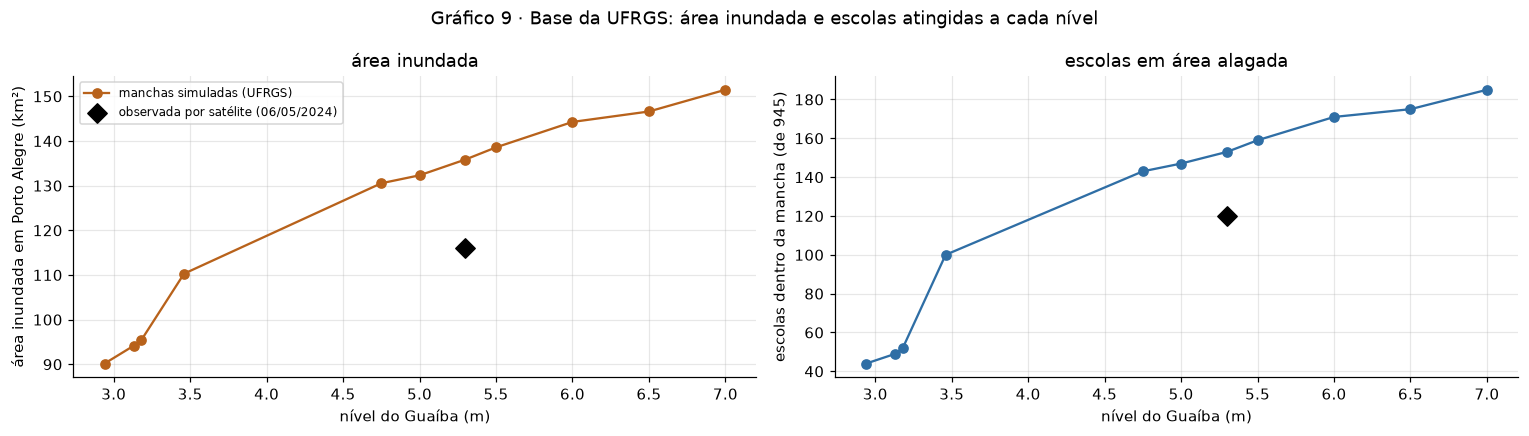

rhguaiba_planet-skysat_inundacao_obs_20240506       \
                                                    sum size   
rede                                                           
Estadual                                             37  240   
Federal                                               1    5   
Municipal                                            14   97   
Privada                                              68  603   

          poa_inundacao_2024_530cm       
                               sum size  
rede                                     
Estadual                        40  240  
Federal                          1    5  
Municipal                       16   97  
Privada                         96  603

In [11]:
ordem = area.drop_duplicates("camada").sort_values("nivel_m")
sim = ordem[ordem.tipo == "simulada"]
km2 = area.groupby("camada").area_inundada_km2.sum()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))
a1.plot(sim.nivel_m, km2[sim.camada].values, marker="o", color=LARANJA, label="manchas simuladas (UFRGS)")
a1.scatter([5.3], [km2[OBS]], marker="D", s=80, color="black", zorder=3, label="observada por satélite (06/05/2024)")
a1.set(xlabel="nível do Guaíba (m)", ylabel="área inundada em Porto Alegre (km²)"); a1.legend(fontsize=8)
a1.set_title("área inundada")
a2.plot(sim.nivel_m, [escolas[c].sum() for c in sim.camada], marker="o", color=AZUL)
a2.scatter([5.3], [escolas[OBS].sum()], marker="D", s=80, color="black", zorder=3)
a2.set(xlabel="nível do Guaíba (m)", ylabel=f"escolas dentro da mancha (de {len(escolas)})")
a2.set_title("escolas em área alagada")
fig.suptitle("Gráfico 9 · Base da UFRGS: área inundada e escolas atingidas a cada nível")
plt.tight_layout(); plt.show()
escolas.groupby("rede")[[OBS, "poa_inundacao_2024_530cm"]].agg(["sum", "size"])

**Leitura:** nas manchas simuladas pela UFRGS, a área inundada no município vai de 90 km² (2,94 m) a 151 km² (7,0 m), com o maior salto entre 3,2 e 4,75 m, a mesma faixa em que a curva do INCT é mais inclinada. A mancha **observada** em 06/05/2024 (116 km²) é menor que a simulada para 5,30 m (136 km²). As escolas seguem o mesmo padrão: de 44 a 185 escolas dentro da mancha, **120 na mancha observada** e 153 na simulada para 5,30 m, de um total de 945.

Essa área inclui terrenos sem prédios (ilhas, banhados, orla), o que ajuda a explicar por que a porcentagem de área é maior que a de prédios.

## 6. Conclusões para o dashboard

1. O `data.json` precisa de limpeza antes de ir para a tela: 17 valores não monotônicos e todas as porcentagens arredondadas para cima.
2. A Tela 1 deve mostrar os dois critérios de ranking (pessoas e porcentagem), porque eles destacam bairros diferentes.
3. A Tela 2 responde à pergunta escolhida na Fase 1: a simulação do INCT concorda com a enchente observada na grande maioria dos bairros (correlação 0,96), e os bairros divergentes são poucos e identificáveis.
4. Limitações que precisam aparecer no dashboard: população afetada é estimativa (distribuição uniforme entre prédios); prédios (INCT) e área (UFRGS) não são a mesma medida; a base da UFRGS é voluntária e a imagem de satélite é de um único dia.

*Registro de uso de IA: este notebook foi escrito com apoio do Claude Code em 11/11/2026 e revisado pelo autor.*